# NN_L14_zeroshot_examples

**Eight random EuroSAT test images with their true class and the zero-shot CLIP prediction.**

Neural Networks and Deep Learning (NN), Lecture 14 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L14/NN_L14_zeroshot_examples/NN_L14_zeroshot_examples.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

correct among the 8 examples = 5   [examples.n_right]


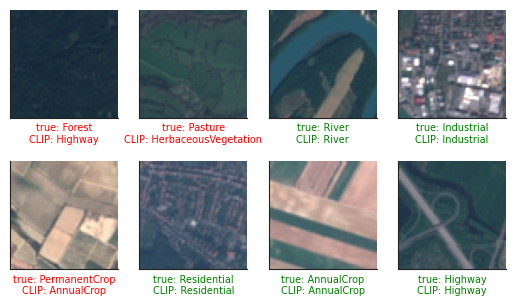

In [3]:
RES = REPO + 'lectures/L14/results/'
import torchvision
root = os.path.join(REPO, 'data', 'raw', 'vision') if os.path.isdir(os.path.join(REPO, 'data')) else 'vision'
os.makedirs(root, exist_ok=True)
ES = torchvision.datasets.EuroSAT(root, download=True)
Z = pd.read_csv(RES + 'eurosat_zeroshot.csv')
best = max([c for c in Z.columns if c[:3] in ('B32', 'B16')], key=lambda c: (Z[c] == Z['true']).mean())
rng = np.random.default_rng(20261108)
yte = Z['true'].map({c: i for i, c in enumerate(ES.classes)}).values
ex = [int(rng.choice(np.where(yte == c)[0])) for c in rng.choice(10, 8, replace=False)]
show('examples.n_right', 'correct among the 8 examples', int(sum(Z[best][e] == Z['true'][e] for e in ex)))
fig, axs = plt.subplots(2, 4, figsize=(6.4, 3.6))
for a, e in zip(axs.ravel(), ex):
    a.imshow(ES[int(Z['index'][e])][0])
    a.set_xticks([]); a.set_yticks([])
    a.set_xlabel(f"true: {Z['true'][e]}\nCLIP: {Z[best][e]}", fontsize=7, color='green' if Z[best][e] == Z['true'][e] else 'red')
fig.savefig('zeroshot_examples.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()